# Flagging Vendor Invoices for Manual Review

**Objective:** Predict whether a vendor invoice should be flagged for manual approval based on abnormal cost, freight, or delivery patterns, in order to reduce financial risk, improve operational efficiency, and prioritize human review where it adds the most value.

- Manual invoice review is time-consuming and does not scale with transaction volume.
- Abnormal freight charges, pricing deviations, or delivery delays often indicate errors, disputes, or compliance risks.
- An automated flagging system enables finance teams to focus attention on high-risk invoices while allowing low-risk invoices to be processed automatically.

In [1]:
import sqlite3 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 


In [2]:
conn = sqlite3.connect('C:/Users/jasme/Downloads/data analyst/New folder/inventory.db')

In [3]:
print(conn)

In [4]:
pd.read_sql_query("""
    SELECT
        p.PONumber,
        COUNT(DISTINCT p.Brand) AS total_brands,
        SUM(p.Quantity) AS total_item_quantity,
        SUM(p.Dollars) AS total_item_dollars,
        AVG(julianday(p.ReceivingDate) - julianday(p.PODate)) AS avg_receiving_delay
    FROM purchases p
    GROUP BY p.PONumber
""", conn)

,PONumber,total_brands,total_item_quantity,total_item_dollars,avg_receiving_delay
0,8106,81,10100,137483.78,12.614130
1,8107,2,24,348.72,12.500000
2,8108,165,8466,60281.13,12.632479
3,8109,23,2246,14298.09,12.626866
4,8110,183,8086,56493.23,12.695271
...,...,...,...,...,...
5538,13657,3,253,3844.39,4.870968
5539,13658,111,14115,102949.38,5.016349
5540,13659,13,338,2492.20,4.735294
5541,13660,12,195,2599.66,4.611111


In [5]:
pd.read_sql_query("""
SELECT
    vi.Quantity AS invoice_quantity,
    vi.Dollars AS invoice_dollars,
    vi.Freight,
    (julianday(vi.InvoiceDate) - julianday(vi.PODate)) AS days_po_to_invoice,
    (julianday(vi.PayDate) - julianday(vi.InvoiceDate)) AS days_to_pay
FROM vendor_invoice vi
""", conn)

,invoice_quantity,invoice_dollars,Freight,days_po_to_invoice,days_to_pay
0,6,214.26,3.47,14.0,43.0
1,15,140.55,8.57,16.0,45.0
2,5,106.60,4.61,16.0,38.0
3,10100,137483.78,2935.20,23.0,24.0
4,1935,15527.25,429.20,14.0,36.0
...,...,...,...,...,...
5538,90,1563.00,8.60,16.0,35.0
5539,4617,37300.48,186.50,18.0,39.0
5540,9848,202815.78,932.95,11.0,33.0
5541,24747,149007.56,819.54,14.0,36.0


In [6]:
df = pd.read_sql_query("""
WITH purchase_summary AS (
    SELECT
        p.PONumber,
        COUNT(DISTINCT p.Brand) AS total_brands,
        SUM(p.Quantity) AS total_item_quantity,
        SUM(p.Dollars) AS total_item_dollars,
        AVG(julianday(p.ReceivingDate) - julianday(p.PODate)) AS avg_receiving_delay
    FROM purchases p
    GROUP BY p.PONumber
),

invoice_summary AS (
    SELECT
        vi.PONumber,
        SUM(vi.Quantity) AS invoice_quantity,
        SUM(vi.Dollars) AS invoice_dollars,
        SUM(vi.Freight) AS total_freight,
        AVG(julianday(vi.InvoiceDate) - julianday(vi.PODate)) AS days_po_to_invoice,
        AVG(julianday(vi.PayDate) - julianday(vi.InvoiceDate)) AS days_to_pay
    FROM vendor_invoice vi
    GROUP BY vi.PONumber
)

SELECT
    ps.PONumber,
    ps.total_brands,
    ps.total_item_quantity,
    ps.total_item_dollars,
    ps.avg_receiving_delay,
    ins.invoice_quantity,
    ins.invoice_dollars,
    ins.total_freight,
    ins.days_po_to_invoice,
    ins.days_to_pay

FROM purchase_summary ps

LEFT JOIN invoice_summary ins
    ON ps.PONumber = ins.PONumber

""", conn)

df.head()

,PONumber,total_brands,total_item_quantity,total_item_dollars,avg_receiving_delay,invoice_quantity,invoice_dollars,total_freight,days_po_to_invoice,days_to_pay
0,8106,81,10100,137483.78,12.614130,10100,137483.78,2935.20,23.0,24.0
1,8107,2,24,348.72,12.500000,24,348.72,9.08,16.0,36.0
2,8108,165,8466,60281.13,12.632479,8466,60281.13,1549.81,22.0,30.0
3,8109,23,2246,14298.09,12.626866,2246,14298.09,408.72,23.0,30.0
4,8110,183,8086,56493.23,12.695271,8086,56493.23,1300.92,20.0,41.0


In [7]:
df.isnull().sum() 

PONumber               0
total_brands           0
total_item_quantity    0
total_item_dollars     0
avg_receiving_delay    0
invoice_quantity       0
invoice_dollars        0
total_freight          0
days_po_to_invoice     0
days_to_pay            0
dtype: int64

In [8]:
df.dtypes

PONumber                 int64
total_brands             int64
total_item_quantity      int64
total_item_dollars     float64
avg_receiving_delay    float64
invoice_quantity         int64
invoice_dollars        float64
total_freight          float64
days_po_to_invoice     float64
days_to_pay            float64
dtype: object

In [9]:
def create_invoice_risk_label(row):

    # Invoice total mismatch with item-level total
    if (abs(row["invoice_dollars"] - row["total_item_dollars"]) > 5):
        return 1

    # Abnormally high receiving delay
    if row["avg_receiving_delay"] > 10:
        return 1

    return 0


df["flag_invoice"] = df.apply(create_invoice_risk_label, axis=1)

df["flag_invoice"].value_counts()

flag_invoice
0    3693
1    1850
Name: count, dtype: int64

<Axes: xlabel='flag_invoice'>

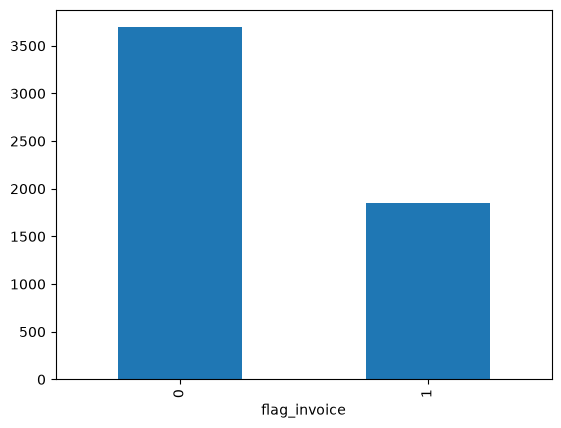

In [10]:
df['flag_invoice'].value_counts().plot(kind = 'bar' )

In [11]:
df.corr()


,PONumber,total_brands,total_item_quantity,total_item_dollars,avg_receiving_delay,invoice_quantity,invoice_dollars,total_freight,days_po_to_invoice,days_to_pay,flag_invoice
PONumber,1.000000,0.013423,0.049442,0.059221,-0.042362,0.049230,0.058917,0.043617,-0.002234,0.012558,0.564946
total_brands,0.013423,1.000000,0.783825,0.753092,0.000496,0.566394,0.536952,0.536381,0.009519,0.020336,0.008961
total_item_quantity,0.049442,0.783825,1.000000,0.963831,-0.014016,0.706117,0.667666,0.656616,0.005543,0.016203,0.032783
total_item_dollars,0.059221,0.753092,0.963831,1.000000,-0.014251,0.668171,0.679537,0.670768,0.007931,0.015610,0.037994
avg_receiving_delay,-0.042362,0.000496,-0.014016,-0.014251,1.000000,0.000519,0.004694,0.015645,0.515538,-0.029403,0.311667
invoice_quantity,0.049230,0.566394,0.706117,0.668171,0.000519,1.000000,0.963831,0.946550,0.000526,0.022284,0.032783
invoice_dollars,0.058917,0.536952,0.667666,0.679537,0.004694,0.963831,1.000000,0.985141,0.001610,0.025661,0.037994
total_freight,0.043617,0.536381,0.656616,0.670768,0.015645,0.946550,0.985141,1.000000,0.003265,0.025513,0.037759
days_po_to_invoice,-0.002234,0.009519,0.005543,0.007931,0.515538,0.000526,0.001610,0.003265,1.000000,-0.370432,0.183115
days_to_pay,0.012558,0.020336,0.016203,0.015610,-0.029403,0.022284,0.025661,0.025513,-0.370432,1.000000,-0.005289


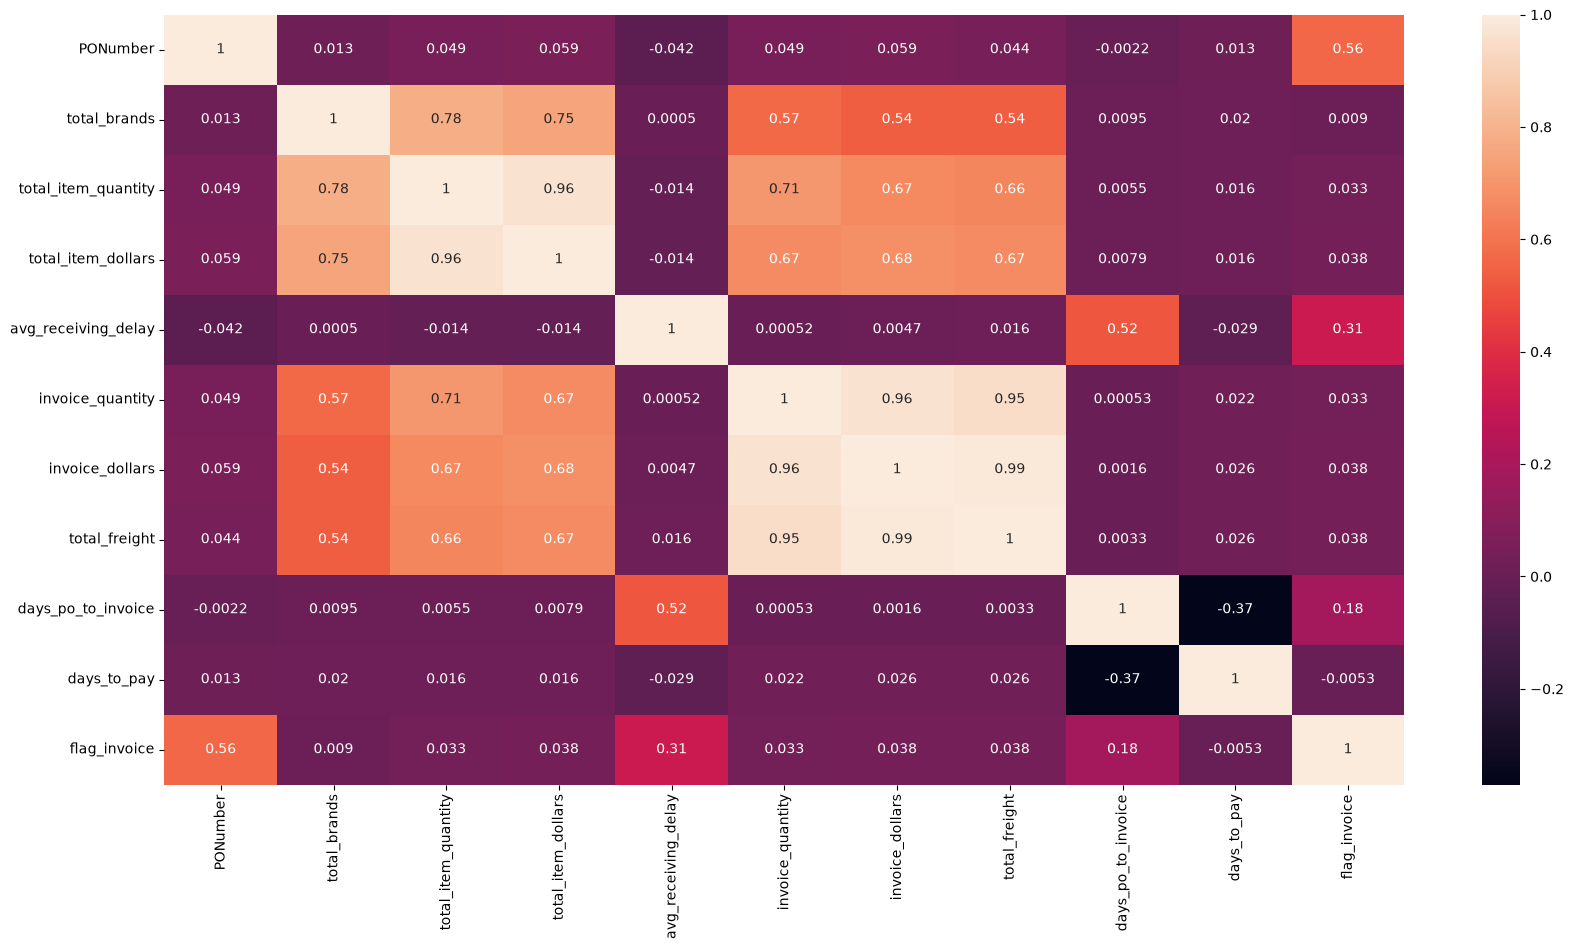

In [12]:
plt.figure(figsize=(20,10)) 
sns.heatmap(df.corr() , annot = True) 
plt.show()


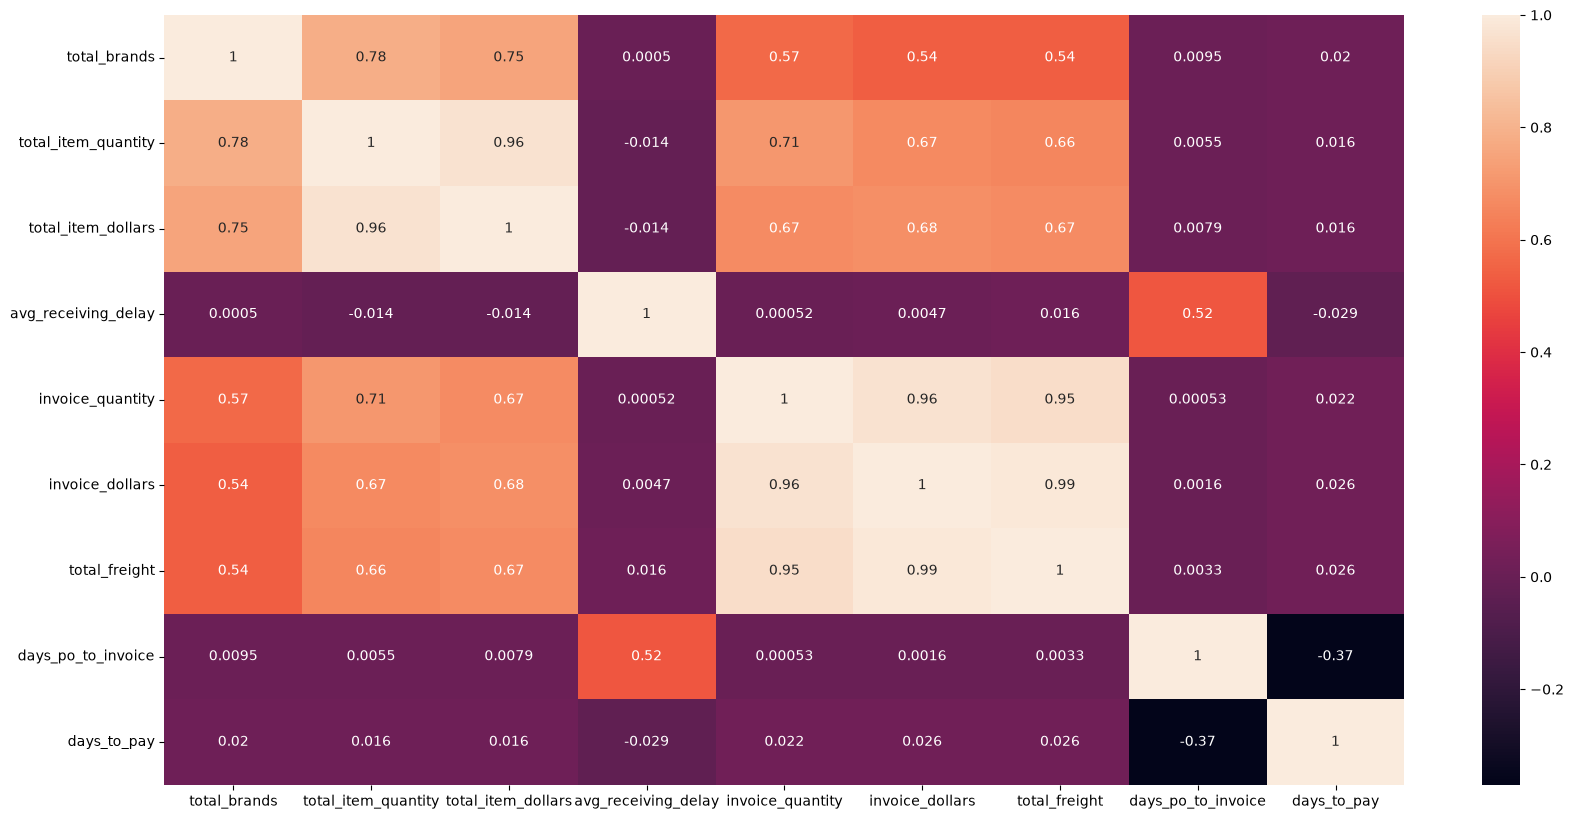

In [13]:
plt.figure(figsize=(20,10))

sns.heatmap(
    df.iloc[:, 1:-1].corr(),
    annot=True
)

plt.show()

In [14]:
flagged = df[df['flag_invoice'] == 1 ] 
normal = df[df['flag_invoice'] == 0 ] 

In [15]:
significant_features = [] 
non_significant_features = [] 
results = [] 

metrics = [
    'invoice_quantity',
    'invoice_dollars',
    'total_freight',
    'days_po_to_invoice',
    'days_to_pay',
    'total_brands',
    'total_item_quantity',
    'total_item_dollars',
    'avg_receiving_delay'
]

In [16]:
from scipy.stats import ttest_ind

In [17]:
for metric in metrics:

    flagged_mean = flagged[metric].mean()
    normal_mean = normal[metric].mean()

    t_stat, p_value = ttest_ind(
        flagged[metric].dropna(),
        normal[metric].dropna(),
        equal_var=False
    )

    if p_value < 0.05:

        significant_features.append(metric)

        results.append({
            "metric": metric,
            "flagged_mean": round(flagged_mean, 2),
            "normal_mean": round(normal_mean, 2),
            "p_value": round(p_value, 3)
        })

    else:
        non_significant_features.append(metric)

In [18]:
print(metrics)
print(df.columns.tolist())

['invoice_quantity', 'invoice_dollars', 'total_freight', 'days_po_to_invoice', 'days_to_pay', 'total_brands', 'total_item_quantity', 'total_item_dollars', 'avg_receiving_delay']
['PONumber', 'total_brands', 'total_item_quantity', 'total_item_dollars', 'avg_receiving_delay', 'invoice_quantity', 'invoice_dollars', 'total_freight', 'days_po_to_invoice', 'days_to_pay', 'flag_invoice']


In [19]:
non_significant_features 

['days_to_pay', 'total_brands']

In [20]:
significant_features 

['invoice_quantity',
 'invoice_dollars',
 'total_freight',
 'days_po_to_invoice',
 'total_item_quantity',
 'total_item_dollars',
 'avg_receiving_delay']

In [21]:
X = df[[
    'invoice_quantity',
    'invoice_dollars',
    'total_freight',
    'total_brands',
    'total_item_quantity',
    'days_po_to_invoice',
    'total_item_dollars'
]]

y = df['flag_invoice']

In [22]:
X.describe().round()

,invoice_quantity,invoice_dollars,total_freight,total_brands,total_item_quantity,days_po_to_invoice,total_item_dollars
count,5543.0,5543.0,5543.0,5543.0,5543.0,5543.0,5543.0
mean,6059.0,58073.0,296.0,41.0,6059.0,16.0,58073.0
std,14453.0,140234.0,714.0,77.0,14453.0,3.0,140234.0
min,1.0,4.0,0.0,1.0,1.0,9.0,4.0
25%,83.0,968.0,5.0,3.0,83.0,14.0,968.0
50%,423.0,4765.0,25.0,7.0,423.0,16.0,4765.0
75%,5100.0,44587.0,230.0,46.0,5100.0,19.0,44587.0
max,141660.0,1660436.0,8468.0,807.0,141660.0,23.0,1660436.0


In [31]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [27]:
from sklearn.linear_model import LogisticRegression 
from sklearn.tree import DecisionTreeClassifier 
from sklearn.ensemble import RandomForestClassifier


In [32]:
model1 = LogisticRegression(random_state = 42) 
model1.fit(X_train_scaled , y_train) 

model2 = DecisionTreeClassifier(random_state = 42 ) 
model2.fit(X_train_scaled , y_train) 

model3 = RandomForestClassifier(random_state = 42) 
model3.fit(X_train_scaled , y_train) 


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [33]:
evaluate_model(model1, X_test_scaled, y_test, 'Logistic Regression')
evaluate_model(model2, X_test_scaled, y_test, 'Decision Tree Classifier')
evaluate_model(model3, X_test_scaled, y_test, 'Random Forest Classifier')


Logistic Regression
--------------------------
Accuracy: 0.6744815148782687
Precision: 0.6451612903225806
Recall: 0.05405405405405406
F1 Score: 0.09975062344139651

Confusion Matrix:
 [[728  11]
 [350  20]]

Classification Report:
               precision    recall  f1-score   support

           0       0.68      0.99      0.80       739
           1       0.65      0.05      0.10       370

    accuracy                           0.67      1109
   macro avg       0.66      0.52      0.45      1109
weighted avg       0.67      0.67      0.57      1109


Decision Tree Classifier
--------------------------
Accuracy: 0.8178539224526601
Precision: 0.727027027027027
Recall: 0.727027027027027
F1 Score: 0.727027027027027

Confusion Matrix:
 [[638 101]
 [101 269]]

Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.86      0.86       739
           1       0.73      0.73      0.73       370

    accuracy                           0.82

In [30]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

def evaluate_model(model, X_test, y_test, model_name):

    y_pred = model.predict(X_test)

    print(f"\n{model_name}")
    print("--------------------------")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, zero_division=0))
    print("Recall:", recall_score(y_test, y_pred, zero_division=0))
    print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
    print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("\nClassification Report:\n", classification_report(y_test, y_pred, zero_division=0))

In [ ]:
model3.feature_importances_ 


In [ ]:
feature_importance = pd.DataFrame({ 
     "feature" : X_train.columns , 
     "importance" : model3.feature_importances_ }).sort_values(by="importance" , ascending = False ) 
feature_importance 

In [ ]:
X = df[['invoice_quantity', 'invoice_dollars', 'total_freight',
        'total_item_quantity',  'total_item_dollars']]

y = df['flag_invoice']

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model3 = RandomForestClassifier(random_state = 42 ) 
model3.fit(X_train_scaled , y_train) 

evaluate_model(model3 , X_test_scaled , y_test , 'Random Forest Classifier ') 



Random Forest Classifier 
--------------------------
Accuracy: 0.8809738503155996
Precision: 0.9578947368421052
Recall: 0.6946564885496184
F1 Score: 0.8053097345132744

Confusion Matrix:
 [[704  12]
 [120 273]]

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.98      0.91       716
           1       0.96      0.69      0.81       393

    accuracy                           0.88      1109
   macro avg       0.91      0.84      0.86      1109
weighted avg       0.89      0.88      0.88      1109



In [35]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, f1_score

rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 4, 5, 6],
    "min_samples_split": [2, 3, 5],
    "min_samples_leaf": [1, 2, 5],
    "criterion": ['gini', 'entropy']
}

scorer = make_scorer(f1_score)

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring=scorer,
    cv=5,
    verbose=2,
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

evaluate_model(grid_search, X_test_scaled, y_test, 'Random Forest Classifier')

Fitting 5 folds for each of 216 candidates, totalling 1080 fits

Random Forest Classifier
--------------------------
Accuracy: 0.8782687105500451
Precision: 0.9640287769784173
Recall: 0.6819338422391857
F1 Score: 0.7988077496274217

Confusion Matrix:
 [[706  10]
 [125 268]]

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.99      0.91       716
           1       0.96      0.68      0.80       393

    accuracy                           0.88      1109
   macro avg       0.91      0.83      0.86      1109
weighted avg       0.89      0.88      0.87      1109



In [37]:
from sklearn.metrics import  confusion_matrix 


In [40]:
confusion_matrix(grid_search.predict(X_test_scaled), y_test)

array([[706, 125],
       [ 10, 268]])

In [39]:
confusion_matrix(model3.predict(X_test_scaled), y_test)

array([[704, 120],
       [ 12, 273]])

In [41]:
grid_search.best_params_

{'criterion': 'gini',
 'max_depth': None,
 'min_samples_leaf': 1,
 'min_samples_split': 5,
 'n_estimators': 300}